# 08 Results, parts 2-3: from prediction to reliable alerts

**Part 2 - what goes wrong when risks become alerts?** When the system moves to another charting system or is used on
different patient groups, the model's ranking holds but its probabilities drift, so a fixed alert threshold silently
changes the alert burden and the share of AKI events caught.

**Part 3 - can the alert burden be guaranteed?** Local recalibration plus a threshold certified to meet a stated
false-alert budget (the method), with its data requirements and limits.

It only reads committed aggregate tables and figures. Numbers are explained in `docs/FINAL-ANALYSES.md`, Parts 2-3.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "pipeline" else Path.cwd()
R = ROOT / "artifacts" / "reports"
FIG = R / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

def show(name, width=820):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## 2.1-2.2 What the locked alert policy achieves
Policy v3 runs at 1.99 false alerts per true alert (the Tomasev et al. operating point) and catches severe AKI best.

,policy,alert_ppv,false_alerts_per_true_alert,event_detection_rate,lead_time_median_h,alerts_per_patient_day
0,policy_v3,0.335,1.986,0.717,11.637,0.418
1,demo_v1,0.340,1.944,0.766,12.936,0.798


,stratum,events,detection_rate_24h,detection_24h_ci_low,detection_24h_ci_high,detection_rate_48h,lead_time_median_h
0,all events,959,0.717,0.688,0.745,0.766,11.637
1,max stage 1,693,0.681,0.645,0.715,0.732,12.005
2,max stage 2,144,0.764,0.688,0.826,0.799,11.330
3,max stage 3,122,0.869,0.798,0.918,0.926,9.508
4,max stage 2-3,266,0.812,0.761,0.854,0.857,10.860
5,went on to RRT,41,0.976,0.874,0.996,0.976,10.672


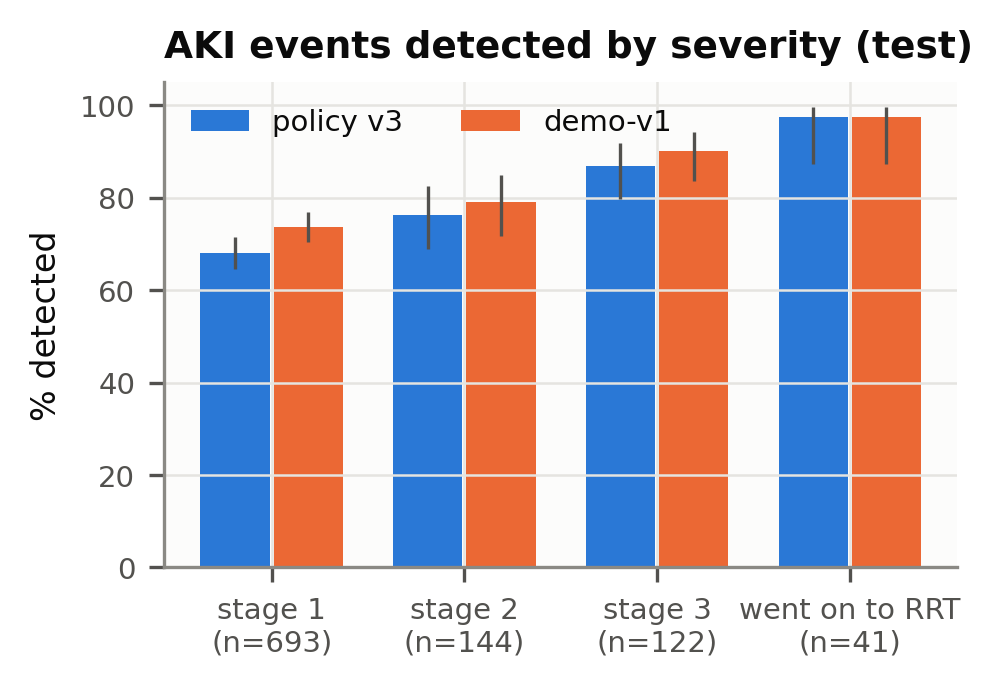

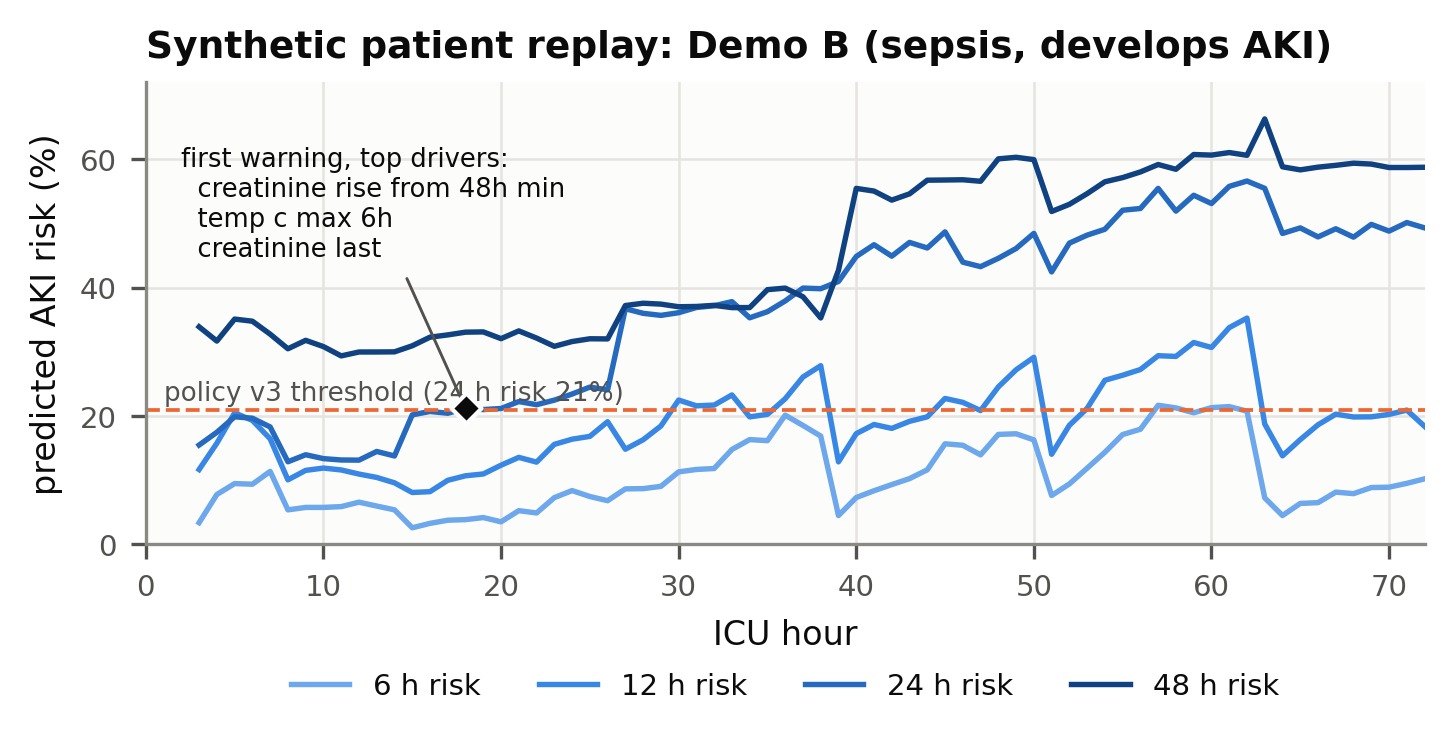

In [2]:
display(pd.read_csv(R / "final_analyses_v1" / "operating_points.csv"))
s = pd.read_csv(R / "final_analyses_v1" / "severity_detection.csv")
display(s[s["policy"] == "policy_v3"][["stratum", "events", "detection_rate_24h", "detection_24h_ci_low", "detection_24h_ci_high", "detection_rate_48h", "lead_time_median_h"]])
show("fig_severity", 560)
show("fig_patient_example")

## 2.3 The alert trade-off and clinical utility
More alerts catch more AKI; the threshold decides where a unit sits on this curve.

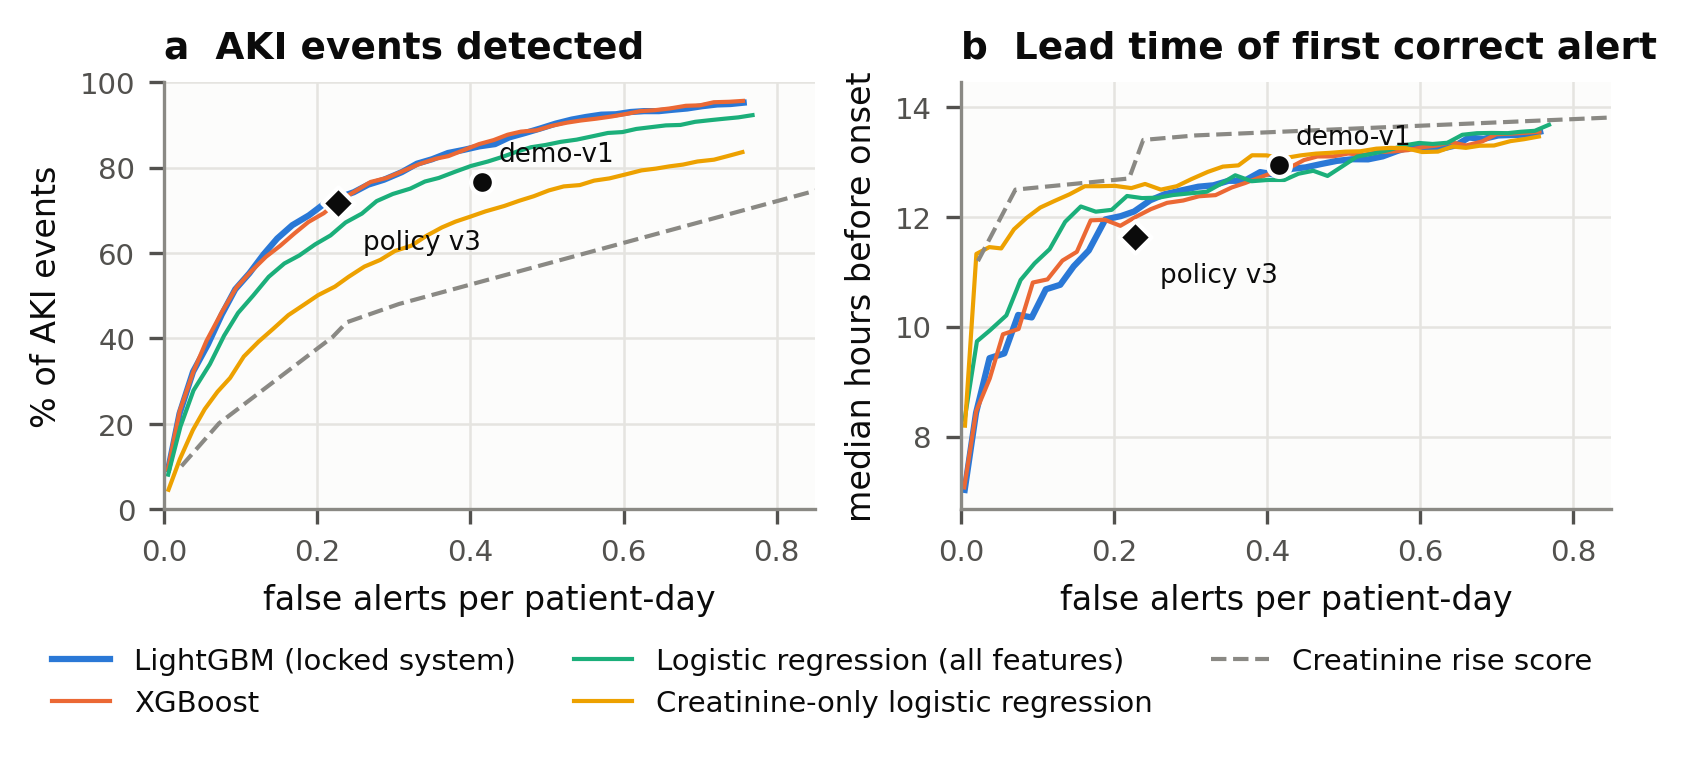

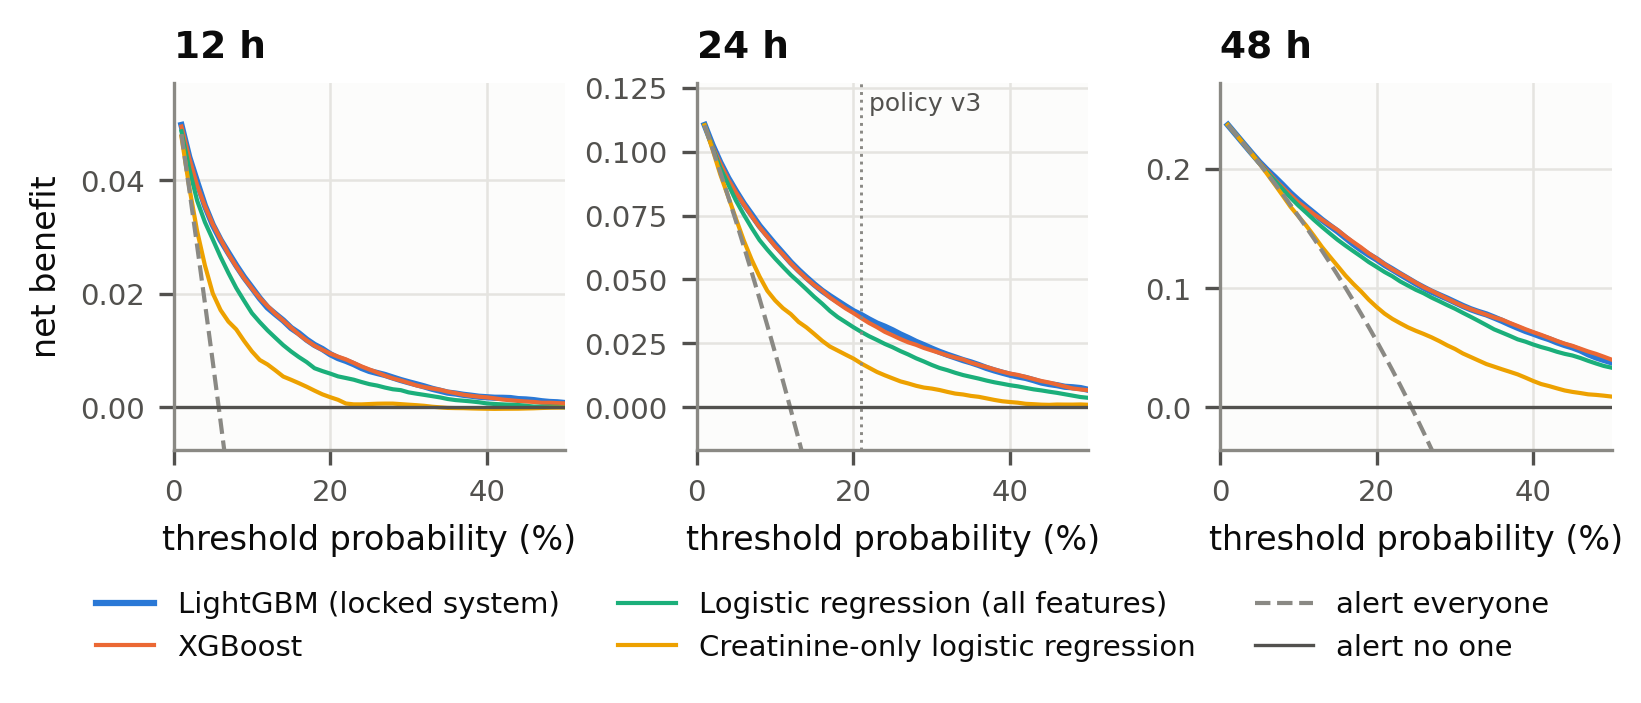

In [3]:
show("fig_alert_tradeoff")
show("fig_decision_curve")

## 2.4 What breaks when the system moves: ranking holds, probabilities drift

,target_system,model,auroc,observed_over_expected,calibration_slope
30,carevue,reference,0.807,0.909,1.015
31,carevue,train_carevue,0.792,0.932,1.007
32,carevue,train_metavision,0.782,0.858,0.976
33,metavision,reference,0.832,1.089,1.143
34,metavision,train_carevue,0.806,1.156,1.126
35,metavision,train_metavision,0.821,1.014,1.090


,model,target_system,event_detection_rate,false_alerts_per_patient_day
0,reference,carevue,0.695,0.249
1,reference,metavision,0.747,0.197
2,train_carevue,carevue,0.649,0.238
3,train_carevue,metavision,0.674,0.190
4,train_metavision,carevue,0.670,0.258
5,train_metavision,metavision,0.758,0.212


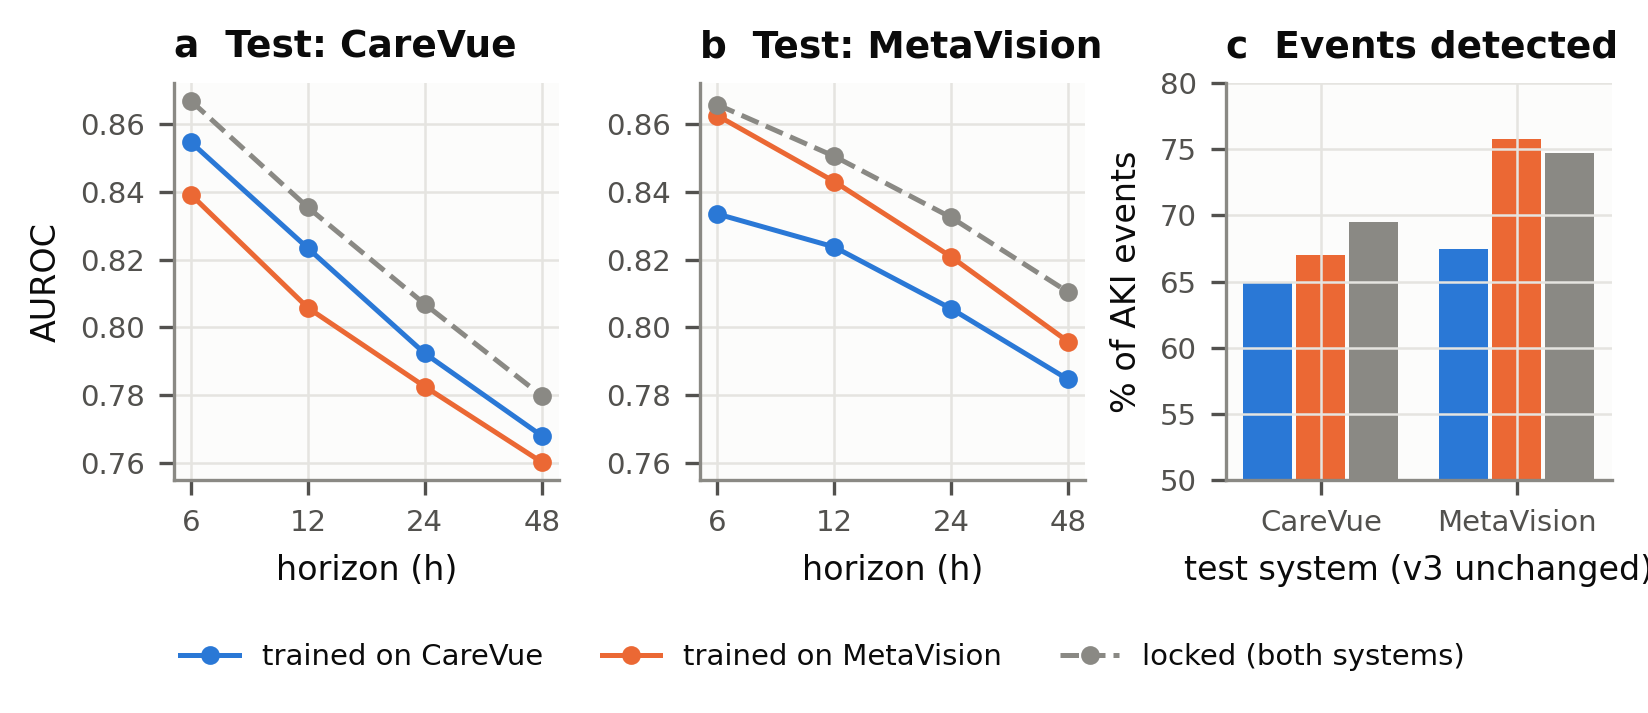

In [4]:
m = pd.read_csv(R / "system_shift_v1" / "snapshot_metrics.csv")
display(m[(m["split"] == "test") & (m["horizon_h"] == 24)][["target_system", "model", "auroc", "observed_over_expected", "calibration_slope"]])
display(pd.read_csv(R / "system_shift_v1" / "alert_metrics_policy_v3.csv")[["model", "target_system", "event_detection_rate", "false_alerts_per_patient_day"]])
show("fig_system_shift")

## 2.5 What differs between patient groups

,variable,level,patients,aki_events,reported,auroc_24h,observed_over_expected,event_detection_rate,false_alerts_per_patient_day
0,insurance,Medicare,2581,568,full,0.818,0.975,0.759,0.279
1,insurance,Private,1751,278,full,0.807,0.906,0.665,0.181
2,insurance,Medicaid,394,70,full,0.813,1.164,0.643,0.150
3,insurance,Government,163,35,full,0.831,1.452,0.629,0.119
4,insurance,Self Pay,70,8,counts only,NaN,NaN,NaN,NaN
5,ethnicity_group,WHITE,3536,645,full,0.820,0.929,0.727,0.227
6,ethnicity_group,BLACK,345,55,full,0.793,1.068,0.727,0.167
7,ethnicity_group,HISPANIC,160,28,full,0.828,1.176,0.536,0.160
8,ethnicity_group,ASIAN,125,23,full,0.852,1.062,0.696,0.172
9,ethnicity_group,OTHER,125,37,full,0.817,1.376,0.730,0.279


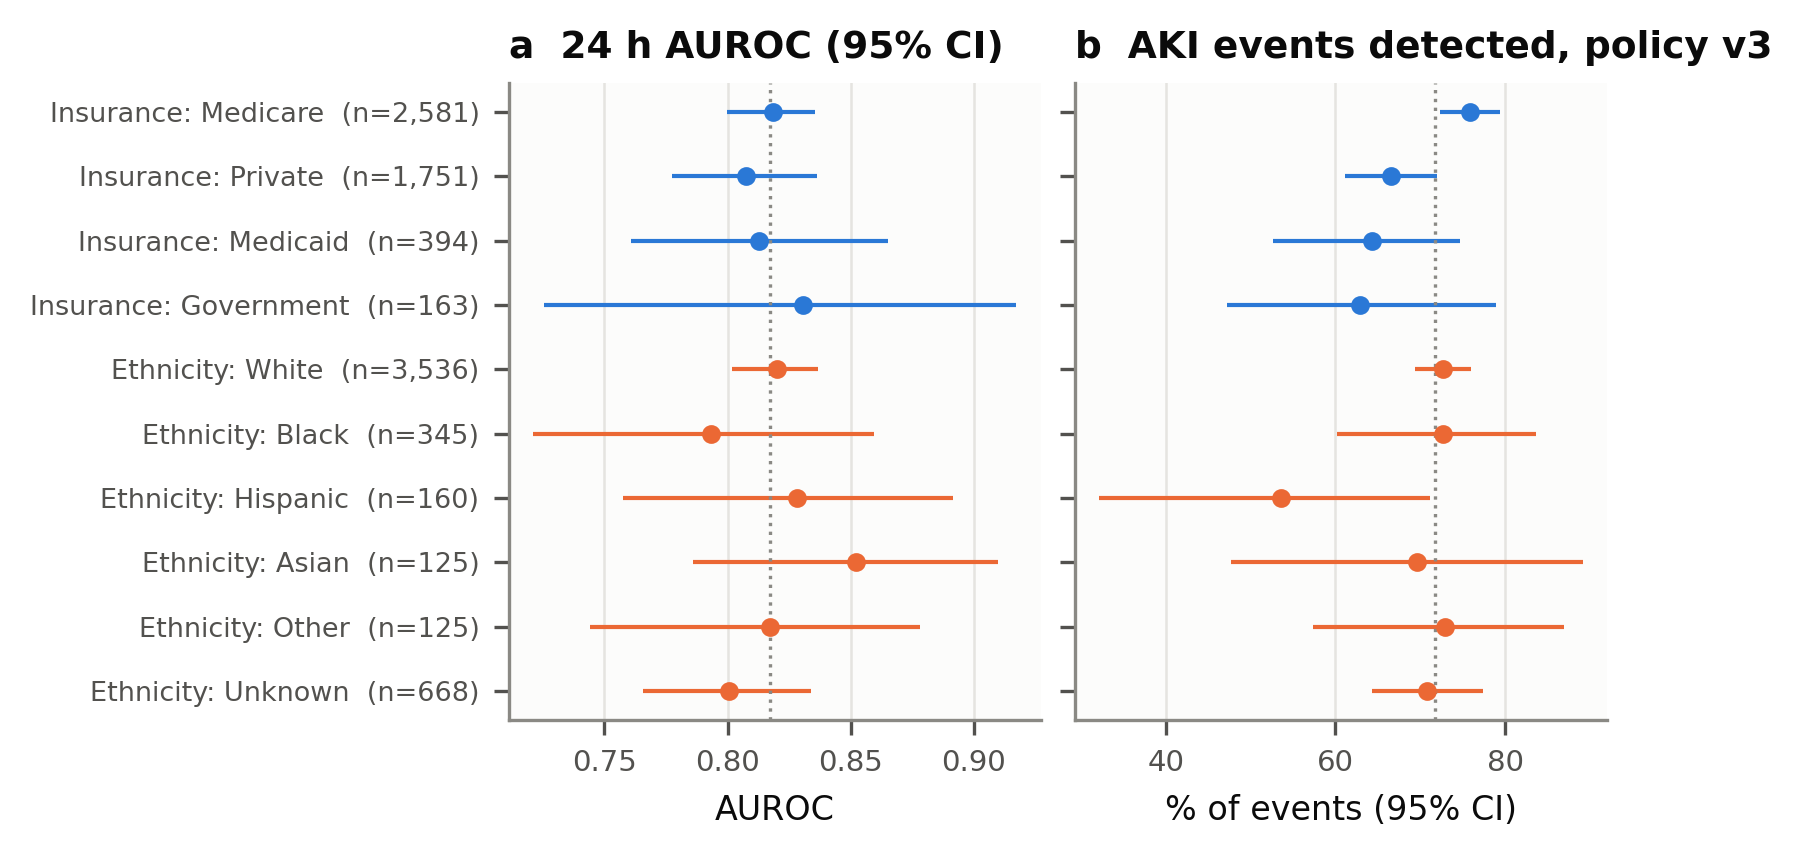

In [5]:
f = pd.read_csv(R / "fairness_structured_v1" / "fairness_by_group.csv")
display(f[f["analysis"] == "test"][["variable", "level", "patients", "aki_events", "reported", "auroc_24h", "observed_over_expected", "event_detection_rate", "false_alerts_per_patient_day"]])
show("fig_fairness")

## 3.1 Local recalibration repairs the probabilities of a moved model

,target_system,model,event_detection_rate,false_alerts_per_patient_day,alert_ppv,alerts_per_patient_day
0,metavision,train_carevue (source calibration),0.674,0.190,0.365,0.371
1,metavision,train_carevue (recalibrated on target validation),0.712,0.224,0.340,0.431
2,metavision,train_metavision (within-system),0.758,0.212,0.373,0.422
3,carevue,train_metavision (source calibration),0.670,0.258,0.297,0.441
4,carevue,train_metavision (recalibrated on target valid...,0.649,0.237,0.308,0.411
5,carevue,train_carevue (within-system),0.649,0.238,0.301,0.415


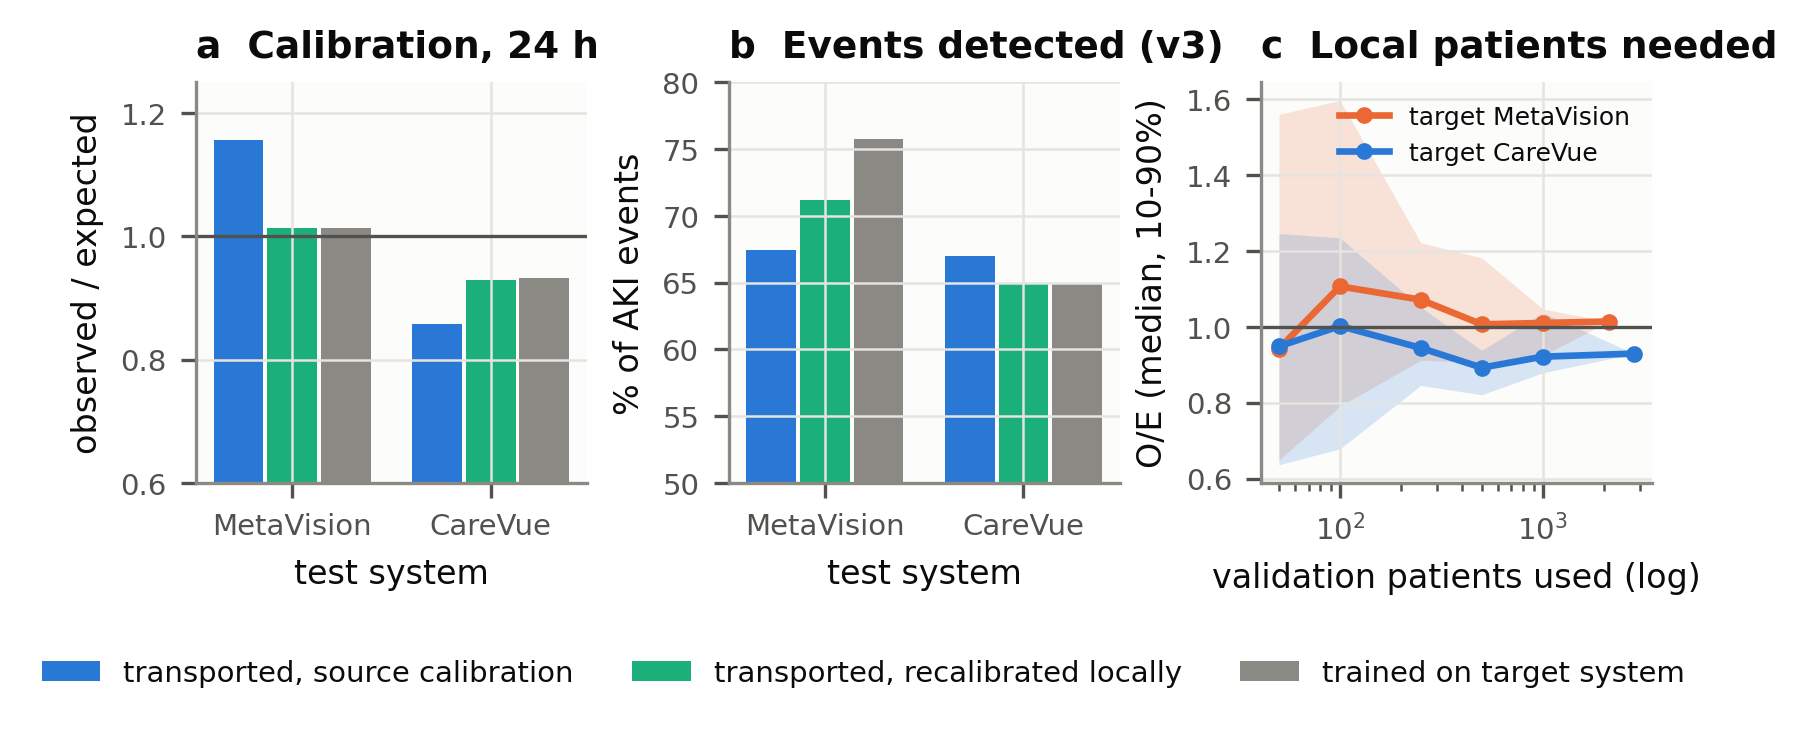

In [6]:
display(pd.read_csv(R / "system_recalibration_v1" / "alert_metrics_policy_v3.csv"))
show("fig_recalibration")

## 3.2 Alert-budget control: a guaranteed alert burden
With local data the 0.25 false-alert budget holds in 98-100% of recalibrations; without local data in 65%.

,setting,method,threshold,false_alerts_per_patient_day,budget_met,event_detection_rate,alert_ppv
0,in_distribution,M0_fixed,0.210,0.227,True,0.717,0.335
1,in_distribution,M1_budget,0.205,0.234,True,0.721,0.330
2,in_distribution,M2_group_budget,0.210,0.231,True,0.721,0.333
3,in_distribution,M3_group_budget_parity,NaN,0.224,True,0.726,0.342
4,shift_to_metavision,M0_fixed,0.210,0.190,True,0.674,0.365
5,shift_to_metavision,M1_naive,0.210,0.190,True,0.674,0.365
6,shift_to_metavision,M1_local,0.200,0.204,True,0.684,0.353
7,shift_to_metavision,M2_local,0.225,0.202,True,0.694,0.358
8,shift_to_carevue,M0_fixed,0.210,0.258,False,0.670,0.297
9,shift_to_carevue,M1_naive,0.215,0.250,True,0.661,0.301


,setting,method,budget,resamples,coverage,false_alerts_median,detection_median,target_coverage
0,in_distribution,M1_budget,0.25,500,0.992,0.234,0.721,0.95
1,in_distribution,M2_group_budget,0.25,500,1.000,0.231,0.721,0.95
2,in_distribution,M3_group_budget_parity,0.25,500,0.998,0.229,0.722,0.95
3,shift_to_metavision,M1_naive,0.25,500,1.000,0.190,0.674,0.95
4,shift_to_metavision,M1_local,0.25,500,1.000,0.204,0.684,0.95
5,shift_to_metavision,M2_local,0.25,500,1.000,0.202,0.694,0.95
6,shift_to_carevue,M1_naive,0.25,500,0.646,0.250,0.661,0.95
7,shift_to_carevue,M1_local,0.25,500,0.976,0.233,0.638,0.95
8,shift_to_carevue,M2_local,0.25,500,0.904,0.236,0.636,0.95


,setting,method,budget,false_alerts_per_patient_day,event_detection_rate
0,in_distribution,M1_budget,0.15,0.139,0.615
1,in_distribution,M2_group_budget,0.15,0.137,0.613
2,in_distribution,M3_group_budget_parity,0.15,0.136,0.611
3,in_distribution,M1_budget,0.20,0.185,0.682
4,in_distribution,M2_group_budget,0.20,0.185,0.679
5,in_distribution,M3_group_budget_parity,0.20,0.183,0.681
6,in_distribution,M1_budget,0.25,0.234,0.721
7,in_distribution,M2_group_budget,0.25,0.231,0.721
8,in_distribution,M3_group_budget_parity,0.25,0.224,0.726
9,in_distribution,M1_budget,0.30,0.277,0.765


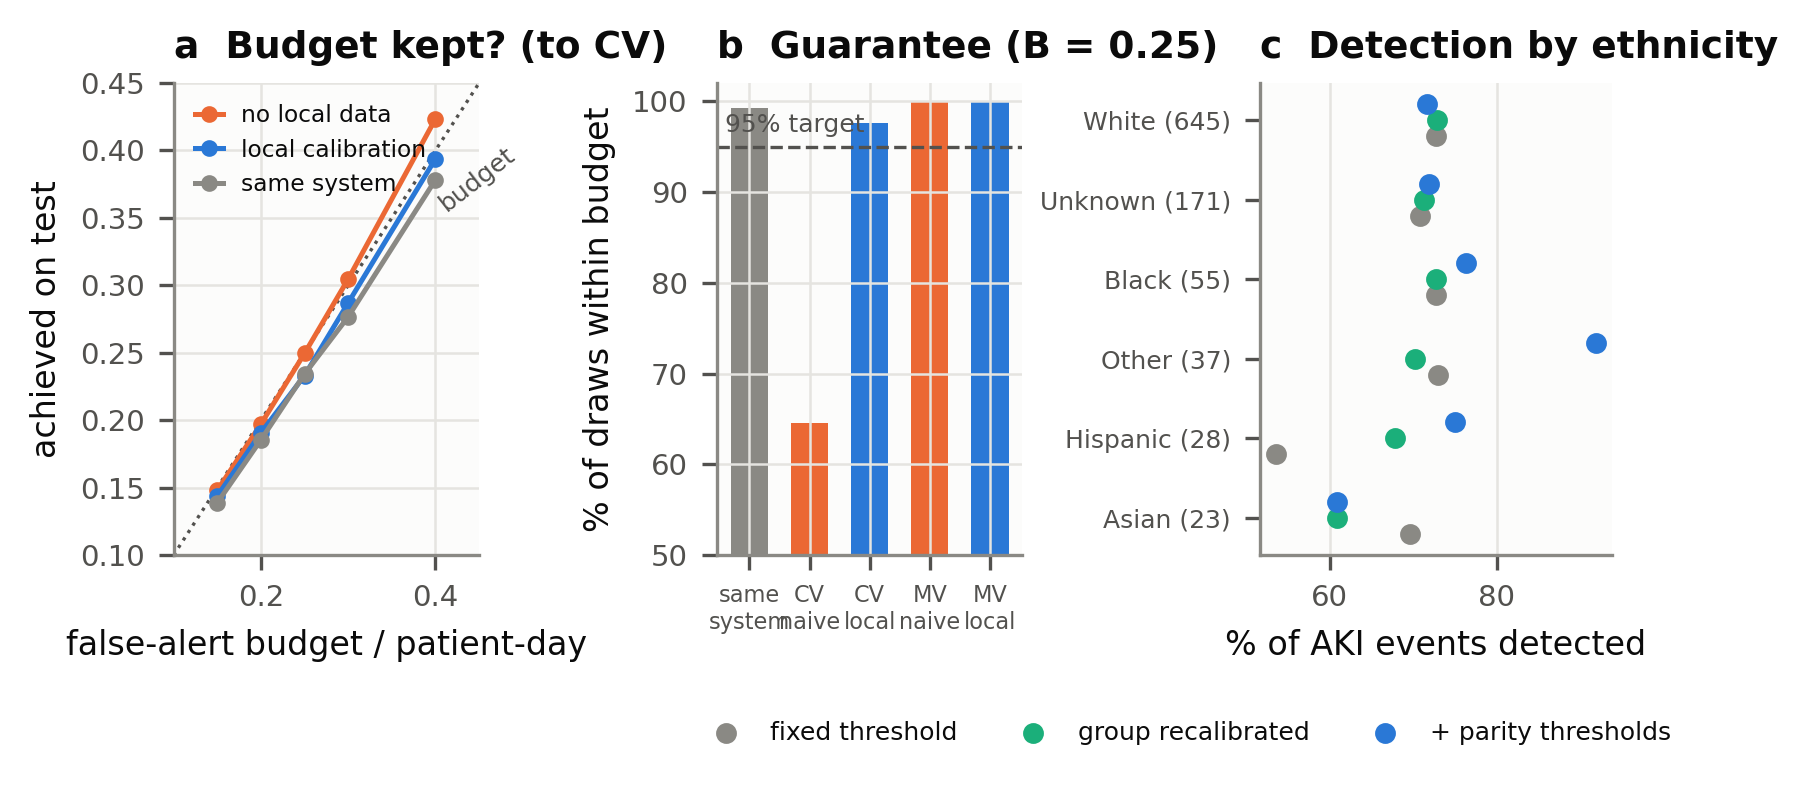

In [7]:
r = pd.read_csv(R / "alert_budget_v1" / "results.csv")
display(r[["setting", "method", "threshold", "false_alerts_per_patient_day", "budget_met", "event_detection_rate", "alert_ppv"]])
display(pd.read_csv(R / "alert_budget_v1" / "coverage.csv"))
display(pd.read_csv(R / "alert_budget_v1" / "budget_sweep.csv")[["setting", "method", "budget", "false_alerts_per_patient_day", "event_detection_rate"]])
show("fig_alert_budget")

## 3.3 Limits: group-specific corrections do not hold up (validation only)

In [8]:
for name in ["fixA_summary", "fixB_summary", "fixC_summary"]:
    display(pd.read_csv(R / "alert_budget_v2_dev" / f"{name}.csv"))

,variant,mean_abs_log_oe
0,P0_none,0.123
1,P1_offsets_V1,0.235
2,P2_offsets_trainOOF,0.170


,variant,false_alerts_per_patient_day,event_detection_rate,alert_ppv,detection_range,detection_worst_group,budget_met,detection_ASIAN,detection_BLACK,detection_HISPANIC,detection_OTHER,detection_UNKNOWN,detection_WHITE
0,P0_single_threshold,0.230,0.724,0.344,0.161,0.621,1.00,0.779,0.723,0.711,0.587,0.689,0.735
1,P1_offsets_V1,0.232,0.718,0.339,0.276,0.523,1.00,0.655,0.740,0.707,0.612,0.675,0.732
2,P2_offsets_trainOOF,0.231,0.729,0.344,0.211,0.601,1.00,0.840,0.759,0.629,0.667,0.704,0.735
3,P3_parity_V1,0.231,0.718,0.340,0.306,0.539,0.95,0.648,0.756,0.698,0.639,0.699,0.725
4,P4_parity_trainOOF,0.230,0.726,0.344,0.203,0.644,1.00,0.772,0.830,0.711,0.696,0.671,0.730


,target_system,variant,coverage,repeats,false_alerts_mean,detection_mean
0,carevue,double_use,0.90,100,0.224,0.634
1,carevue,split,0.90,100,0.215,0.612
2,metavision,double_use,0.86,100,0.226,0.628
3,metavision,split,0.94,100,0.213,0.601
